<a href="https://colab.research.google.com/github/rosin21/Tumour_cellular_automaton_project/blob/main/tumour_cellular_automaton_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A Simple Cellular Automaton Model of Tumour Growth and Spatial Spread

**Author:** Rosin Jimmy  
**Project type:** Exploratory computational modelling project  
**Tools:** Python, NumPy, pandas, Matplotlib

## Project overview
This project investigates how cell proliferation (division) and migration influence population size and spatial spread in a simple stochastic, two-dimensional lattice model. The model represents cells on a grid and explores how different probabilities of division and migration affect the simulated population over time.

**Research question:** How do division and migration probabilities influence the population size and spatial spread of a simulated cell population?

This is a simplified educational model. It is **not** a validated biological tumour model and does not make clinical predictions.

### Reproducibility
The notebook is organized into sequential sections covering the model implementation, simulation experiments, and analysis of results. Run all cells in order to reproduce the analysis. Random seeds are fixed for reproducibility in the same software environment. If model parameters or assumptions are changed, rerun the notebook to regenerate the results.


## 1. Research objectives

The project has four objectives:

1. Migration and spatial spread: Investigate how changing the migration probability affects spatial spread when cell division is disabled.

2. Proliferation and spatial spread: Examine how changing the division probability influences population size and spatial spread while keeping the migration probability fixed.

3. Combined effects: Compare four conditions—baseline, migration only, proliferation only, and combined proliferation and migration—to explore their individual and combined effects.

4. Implementation sensitivity: Investigate whether allowing a migrating cell's vacated site to be reused for division within the same time step substantially changes the simulation results.

## 2. Model assumptions

| Component | Assumption |
|---|---|
| Space | An 80 × 80 square grid |
| Initial population | A central 5 × 5 square, containing 25 cells |
| Cell state | Each grid location is either empty (0) or occupied (1) |
| Neighbourhood | Moore neighbourhood: up to eight adjacent locations |
| Division | A cell may place one daughter cell in a randomly selected empty neighbour |
| Migration | A cell may move to a randomly selected empty neighbour |
| Time | 30 discrete time steps per simulation |
| Randomness | Events and eligible neighbours are selected stochastically |
| Boundaries | Cells cannot move outside the grid |
| Omitted biology | No nutrients, cell death, treatment, tissue mechanics, or experimental data |

The probabilities are per-cell event probabilities per time step. Division and migration are mutually exclusive events in a given cell's turn; the model requires `p_div + p_mig <= 1`.

**Important limitation:** This is a minimal cellular automaton designed to study model behaviour, not to reproduce the full biology of a tumour.


## 3. Setup

The next cell imports the required libraries and defines the main simulation settings. The notebook uses only common Python scientific-computing packages available in Google Colab.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Shared settings used throughout the notebook
GRID_SIZE = 80
STEPS = 30
N_RUNS = 10
SEEDS = range(N_RUNS)

INITIAL_SIDE_LENGTH = 5
INITIAL_CELL_COUNT = INITIAL_SIDE_LENGTH ** 2

print("Grid size:", GRID_SIZE, "×", GRID_SIZE)
print("Initial cells:", INITIAL_CELL_COUNT)
print("Time steps per simulation:", STEPS)
print("Stochastic runs per condition:", N_RUNS)


Grid size: 80 × 80
Initial cells: 25
Time steps per simulation: 30
Stochastic runs per condition: 10


## 4. Define the model

We will define the model only once and reuse the same functions in every experiment.

- `get_neighbours()` returns the valid neighbouring grid locations.
- `initialise_grid()` places the initial 5 × 5 population at the centre.
- `simulate_step()` advances the model by one time step.
- `run_model()` runs a full simulation and records population size over time.
- `measure_spread()` calculates the 95th percentile of cell distances from the original grid centre.

The spread measure is in **grid units**. It is a simple summary of how far the outer part of the population extends; it is not a physical distance in millimetres.


In [2]:
def get_neighbours(i, j, size):
    """Return valid Moore-neighbour locations around grid[i, j]."""
    neighbours = []
    for di in (-1, 0, 1):
        for dj in (-1, 0, 1):
            if di == 0 and dj == 0:
                continue
            ni, nj = i + di, j + dj
            if 0 <= ni < size and 0 <= nj < size:
                neighbours.append((ni, nj))
    return neighbours


def initialise_grid(grid_size=GRID_SIZE):
    """Create a grid with a central 5 × 5 square of occupied locations."""
    grid = np.zeros((grid_size, grid_size), dtype=int)
    centre = grid_size // 2
    half = INITIAL_SIDE_LENGTH // 2
    grid[
        centre - half:centre + half + 1,
        centre - half:centre + half + 1
    ] = 1
    return grid


def simulate_step(
    grid,
    p_div,
    p_mig,
    rng,
    allow_division_into_migration_vacated=True
):
    """Advance the grid by one stochastic time step.

    Cells present at the start of the step are considered in random order.
    A cell can attempt division, migration, or neither. A daughter cell
    created during this step does not get its own turn until a later step.
    """
    if p_div < 0 or p_mig < 0 or p_div + p_mig > 1:
        raise ValueError(
            "Probabilities must be non-negative and p_div + p_mig <= 1."
        )

    new_grid = grid.copy()
    existing_cells = np.argwhere(grid == 1)
    rng.shuffle(existing_cells)

    # Sites occupied at the beginning of this time step
    initially_occupied = set(map(tuple, existing_cells))
    # Sites vacated by migration during this time step
    vacated_by_migration = set()

    for i, j in existing_cells:
        i, j = int(i), int(j)

        # Skip a cell if it has already moved from its original location.
        if new_grid[i, j] != 1:
            continue

        event = rng.random()
        neighbours = get_neighbours(i, j, grid.shape[0])

        if event < p_div:
            empty_locations = [
                (ni, nj)
                for ni, nj in neighbours
                if new_grid[ni, nj] == 0
                and (
                    allow_division_into_migration_vacated
                    or (ni, nj) not in vacated_by_migration
                )
            ]

            if empty_locations:
                ni, nj = empty_locations[rng.integers(len(empty_locations))]
                new_grid[ni, nj] = 1

        elif event < p_div + p_mig:
            empty_locations = [
                (ni, nj)
                for ni, nj in neighbours
                if new_grid[ni, nj] == 0
                and (ni, nj) not in initially_occupied
            ]

            if empty_locations:
                ni, nj = empty_locations[rng.integers(len(empty_locations))]
                new_grid[i, j] = 0
                vacated_by_migration.add((i, j))
                new_grid[ni, nj] = 1

    return new_grid


def run_model(
    p_div,
    p_mig,
    seed=42,
    steps=STEPS,
    grid_size=GRID_SIZE,
    allow_division_into_migration_vacated=True
):
    """Run one simulation; return the final grid and population history."""
    rng = np.random.default_rng(seed)
    grid = initialise_grid(grid_size)
    history = [int(grid.sum())]

    for _ in range(steps):
        grid = simulate_step(
            grid=grid,
            p_div=p_div,
            p_mig=p_mig,
            rng=rng,
            allow_division_into_migration_vacated=(
                allow_division_into_migration_vacated
            )
        )
        history.append(int(grid.sum()))

    return grid, history


def measure_spread(grid):
    """Return the 95th percentile of distances from the grid centre."""
    occupied = np.argwhere(grid == 1)

    if len(occupied) == 0:
        return 0.0

    centre = np.array([grid.shape[0] // 2, grid.shape[1] // 2])
    distances = np.sqrt(((occupied - centre) ** 2).sum(axis=1))
    return float(np.percentile(distances, 95))


Initial population: 25
Final population: 25
Spread radius: 2.83


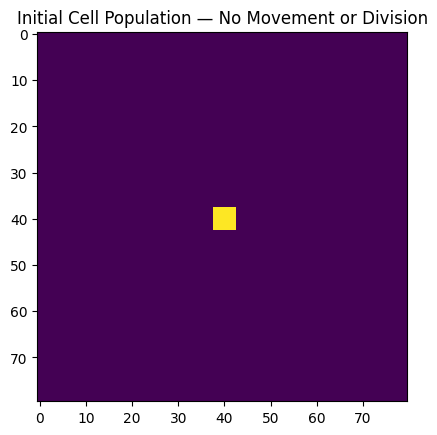

In [3]:

# Test whether the model functions work

grid, history = run_model(
    p_div=0.0,
    p_mig=0.0,
    seed=42
)

print("Initial population:", history[0])
print("Final population:", int(grid.sum()))
print("Spread radius:", round(measure_spread(grid), 2))

import matplotlib.pyplot as plt

plt.imshow(grid)
plt.title("Initial Cell Population — No Movement or Division")
plt.show()


## 5. Basic verification checks

Before running the experiments, check a simple case where both division and migration are disabled. The population should remain at 25 cells for every time step, and the grid should not change.


In [4]:
grid_test, history_test = run_model(
    p_div=0.0,
    p_mig=0.0,
    seed=42
)

assert int(grid_test.sum()) == INITIAL_CELL_COUNT
assert all(n == INITIAL_CELL_COUNT for n in history_test)
assert grid_test.shape == (GRID_SIZE, GRID_SIZE)

print("Basic checks passed.")
print("Initial population:", history_test[0])
print("Final population:", history_test[-1])
print("Spread radius:", round(measure_spread(grid_test), 2))


Basic checks passed.
Initial population: 25
Final population: 25
Spread radius: 2.83


## 6. Visual example: final spatial patterns and population histories

The next cell shows one example run for each of four conditions. These are **illustrative single simulations**, not averages. The fixed seed makes these example runs reproducible in the same software environment.


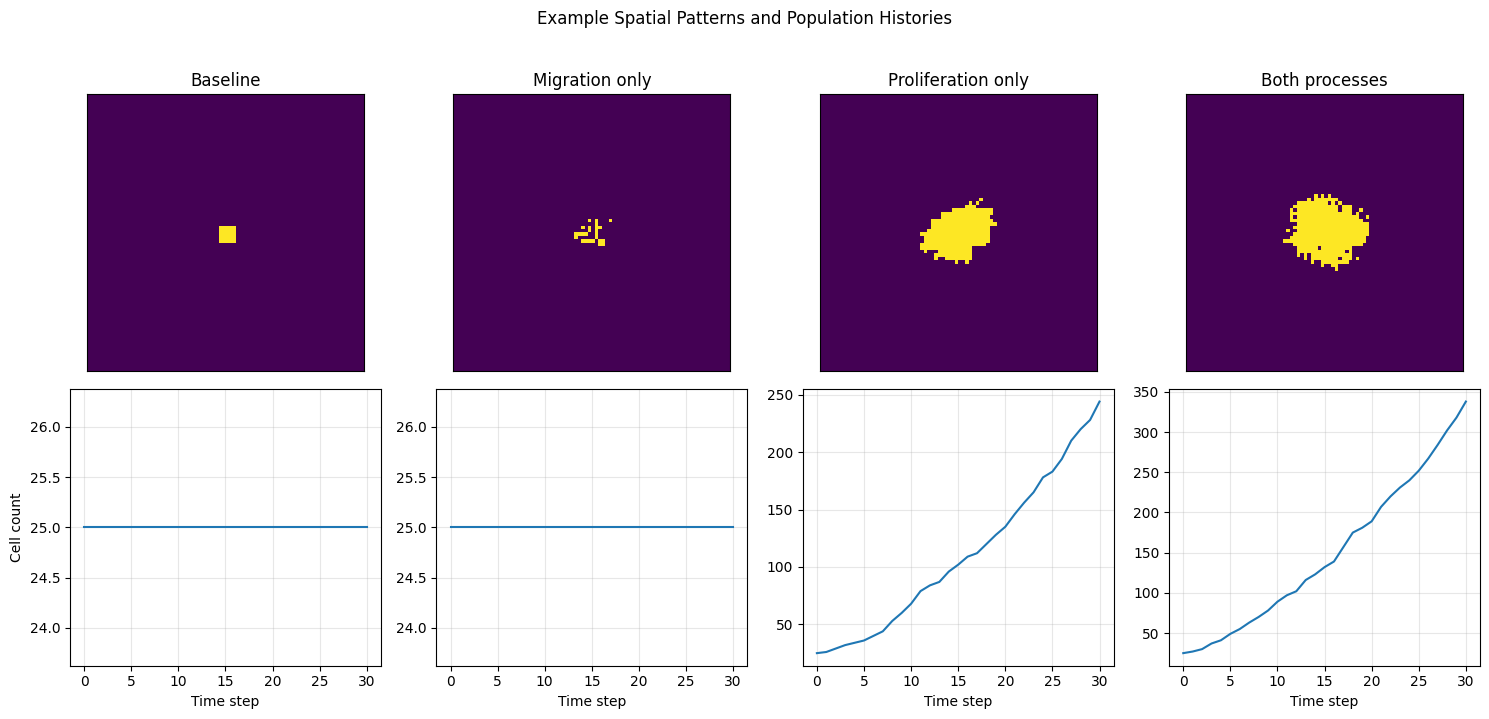

In [5]:
example_conditions = [
    ("Baseline", 0.0, 0.0),
    ("Migration only", 0.0, 0.10),
    ("Proliferation only", 0.15, 0.0),
    ("Both processes", 0.15, 0.10),
]

fig, axes = plt.subplots(2, 4, figsize=(15, 7))

for col, (name, p_div, p_mig) in enumerate(example_conditions):
    grid, history = run_model(p_div=p_div, p_mig=p_mig, seed=42)

    axes[0, col].imshow(grid, interpolation="nearest")
    axes[0, col].set_title(name)
    axes[0, col].set_xticks([])
    axes[0, col].set_yticks([])

    axes[1, col].plot(range(len(history)), history)
    axes[1, col].set_xlabel("Time step")
    axes[1, col].set_ylabel("Cell count" if col == 0 else "")
    axes[1, col].grid(True, alpha=0.3)

fig.suptitle("Example Spatial Patterns and Population Histories", y=1.02)
fig.tight_layout()
plt.show()


## 7. Experiment 1 — Effect of migration probability

**Question:** How does migration probability affect spatial spread when proliferation is disabled?

We set `p_div = 0` and test five migration probabilities. Ten simulations are run for each value. Because division is disabled, the population should remain at 25 cells; the main outcome of interest is the spread radius.

The error bars in the plot represent **one standard deviation** across the 10 simulations. They are not confidence intervals.


,Migration probability,Mean_cells,SD_cells,Mean_spread,SD_spread
0,0.00,25.0,0.0,2.83,0.00
1,0.05,25.0,0.0,4.58,0.34
2,0.10,25.0,0.0,5.16,0.43
3,0.20,25.0,0.0,6.62,0.74
4,0.30,25.0,0.0,7.27,0.68


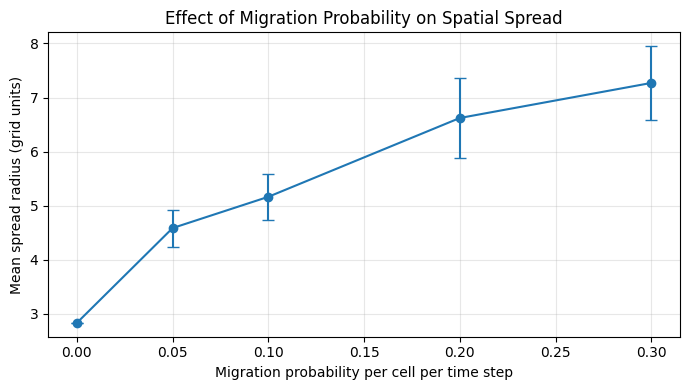

In [6]:
migration_rates = [0.0, 0.05, 0.10, 0.20, 0.30]
records_migration = []

for p_mig in migration_rates:
    for seed in SEEDS:
        grid, history = run_model(
            p_div=0.0,
            p_mig=p_mig,
            seed=seed
        )
        records_migration.append({
            "Migration probability": p_mig,
            "Seed": seed,
            "Final cells": int(grid.sum()),
            "Spread radius": measure_spread(grid)
        })

df_migration = pd.DataFrame(records_migration)

summary_migration = (
    df_migration.groupby("Migration probability")
    .agg(
        Mean_cells=("Final cells", "mean"),
        SD_cells=("Final cells", "std"),
        Mean_spread=("Spread radius", "mean"),
        SD_spread=("Spread radius", "std")
    )
    .reset_index()
)

display(summary_migration.round(2))

plt.figure(figsize=(7, 4))
plt.errorbar(
    summary_migration["Migration probability"],
    summary_migration["Mean_spread"],
    yerr=summary_migration["SD_spread"].fillna(0),
    marker="o",
    capsize=4
)
plt.xlabel("Migration probability per cell per time step")
plt.ylabel("Mean spread radius (grid units)")
plt.title("Effect of Migration Probability on Spatial Spread")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("experiment_1_migration_sensitivity.png", dpi=200, bbox_inches="tight")
plt.show()

# Check that the population stays constant when division is disabled.
assert (df_migration["Final cells"] == INITIAL_CELL_COUNT).all()


### Interpretation — Experiment 1: Effect of Migration on Spatial Spread

The simulation results show that increasing the migration probability is associated with greater spatial spread, while the population size remains constant at 25 cells. Across the tested migration probabilities, the mean spread increased from 2.83 grid units when migration was disabled (\(p_{\mathrm{mig}}=0\)) to 7.27 grid units at \(p_{\mathrm{mig}}=0.30\).

Since cell division is disabled in this experiment, migration redistributes the existing cells across the lattice without increasing their total number. These results illustrate how cell movement can influence the spatial distribution of a population independently of proliferation.

**Limitation:** This trend describes the behaviour of the implemented simulation. It does not establish a quantitative relationship between cell migration and tumour invasion in real biological systems.

## 8. Experiment 2 — Effect of division probability

**Question:** How does division probability affect population size and spatial spread when migration is fixed at 0.10?

We vary the division probability and measure both final cell count and spread radius. Each parameter value is evaluated across 10 stochastic simulations.


,Division probability,Mean_cells,SD_cells,Mean_spread,SD_spread
0,0.00,25.0,0.00,5.16,0.43
1,0.05,86.1,12.83,6.80,0.48
2,0.10,191.6,17.65,8.74,0.57
3,0.15,321.4,37.54,10.84,0.63
4,0.20,478.9,29.16,12.69,0.35


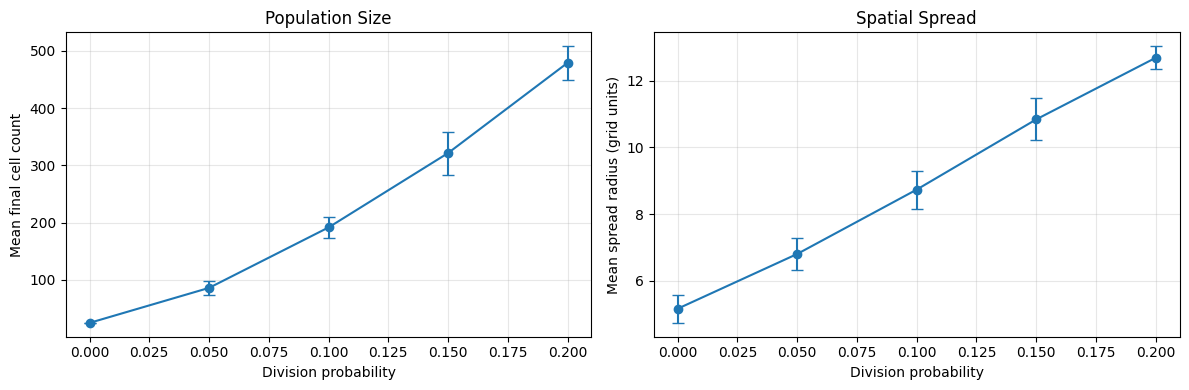

In [7]:
division_rates = [0.0, 0.05, 0.10, 0.15, 0.20]
fixed_migration = 0.10
records_division = []

for p_div in division_rates:
    for seed in SEEDS:
        grid, history = run_model(
            p_div=p_div,
            p_mig=fixed_migration,
            seed=seed
        )
        records_division.append({
            "Division probability": p_div,
            "Seed": seed,
            "Final cells": int(grid.sum()),
            "Spread radius": measure_spread(grid)
        })

df_division = pd.DataFrame(records_division)

summary_division = (
    df_division.groupby("Division probability")
    .agg(
        Mean_cells=("Final cells", "mean"),
        SD_cells=("Final cells", "std"),
        Mean_spread=("Spread radius", "mean"),
        SD_spread=("Spread radius", "std")
    )
    .reset_index()
)

display(summary_division.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].errorbar(
    summary_division["Division probability"],
    summary_division["Mean_cells"],
    yerr=summary_division["SD_cells"].fillna(0),
    marker="o",
    capsize=4
)
axes[0].set_xlabel("Division probability")
axes[0].set_ylabel("Mean final cell count")
axes[0].set_title("Population Size")
axes[0].grid(True, alpha=0.3)

axes[1].errorbar(
    summary_division["Division probability"],
    summary_division["Mean_spread"],
    yerr=summary_division["SD_spread"].fillna(0),
    marker="o",
    capsize=4
)
axes[1].set_xlabel("Division probability")
axes[1].set_ylabel("Mean spread radius (grid units)")
axes[1].set_title("Spatial Spread")
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig("experiment_2_division_sensitivity.png", dpi=200, bbox_inches="tight")
plt.show()


### Interpretation — Experiment 2: Effect of Division Probability

The simulation results indicate that increasing the division probability is associated with increases in both the mean final population size and the mean spatial spread, while the migration probability remains fixed at \(p_{\mathrm{mig}}=0.10\).

Across the tested division probabilities, the mean final population increased from 25 cells when division was disabled (\(p_{\mathrm{div}}=0\)) to 478.9 cells at \(p_{\mathrm{div}}=0.20\). Over the same range, the mean spread radius increased from 5.16 to 12.69 grid units.

Variability across simulation runs was also observed. At non-zero division probabilities, the standard deviation of the final population ranged from 12.83 to 37.54 cells, whereas the standard deviation of the spread radius ranged from 0.35 to 0.63 grid units. This illustrates that stochastic simulations can produce different outcomes even when the model parameters are identical.

**Limitation:** Population size and spatial spread increase together in this experiment. Therefore, the observed increase in spread cannot be attributed to proliferation independently of its effect on population size. Additional experiments controlling for population size would be needed to investigate that relationship more directly.


## 9. Experiment 3 — Four-condition comparison

**Question:** How do migration and proliferation compare individually and when enabled together?

| Condition | Division probability | Migration probability |
|---|---:|---:|
| Baseline | 0.00 | 0.00 |
| Migration only | 0.00 | 0.10 |
| Proliferation only | 0.15 | 0.00 |
| Both processes | 0.15 | 0.10 |

Each condition is run 10 times. The same seed labels are reused across conditions for reproducibility, but because the conditions consume random numbers differently, these are not perfectly matched stochastic trajectories.


,Condition,Mean_cells,SD_cells,Mean_spread,SD_spread
0,Baseline,25.0,0.00,2.83,0.00
1,Migration only,25.0,0.00,5.16,0.43
2,Proliferation only,227.8,18.00,9.02,0.47
3,Both processes,321.4,37.54,10.84,0.63


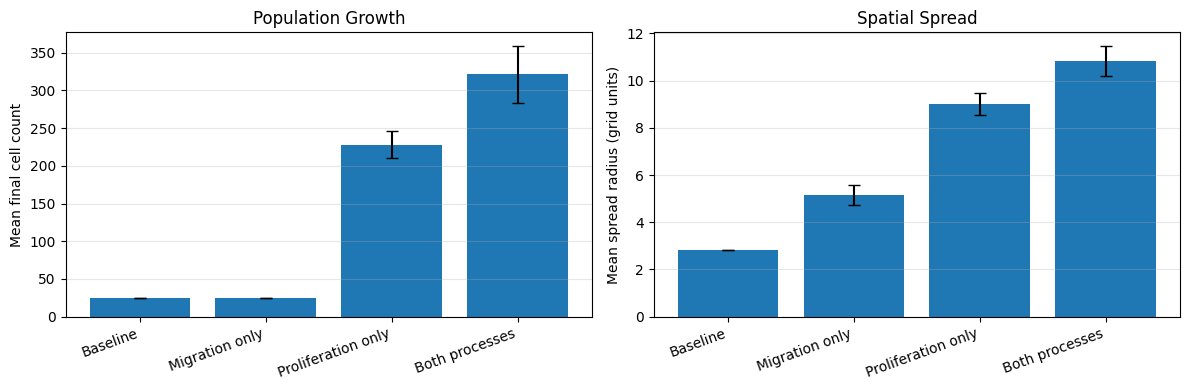

In [8]:
conditions = {
    "Baseline": (0.0, 0.0),
    "Migration only": (0.0, 0.10),
    "Proliferation only": (0.15, 0.0),
    "Both processes": (0.15, 0.10),
}

records_factorial = []

for condition, (p_div, p_mig) in conditions.items():
    for seed in SEEDS:
        grid, history = run_model(
            p_div=p_div,
            p_mig=p_mig,
            seed=seed
        )
        records_factorial.append({
            "Condition": condition,
            "Seed": seed,
            "Division probability": p_div,
            "Migration probability": p_mig,
            "Final cells": int(grid.sum()),
            "Spread radius": measure_spread(grid)
        })

df_factorial = pd.DataFrame(records_factorial)

summary_factorial = (
    df_factorial.groupby("Condition", sort=False)
    .agg(
        Mean_cells=("Final cells", "mean"),
        SD_cells=("Final cells", "std"),
        Mean_spread=("Spread radius", "mean"),
        SD_spread=("Spread radius", "std")
    )
    .reset_index()
)

display(summary_factorial.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(summary_factorial))
labels = summary_factorial["Condition"]

axes[0].bar(
    x,
    summary_factorial["Mean_cells"],
    yerr=summary_factorial["SD_cells"].fillna(0),
    capsize=4
)
axes[0].set_xticks(x, labels, rotation=20, ha="right")
axes[0].set_ylabel("Mean final cell count")
axes[0].set_title("Population Growth")
axes[0].grid(True, axis="y", alpha=0.3)

axes[1].bar(
    x,
    summary_factorial["Mean_spread"],
    yerr=summary_factorial["SD_spread"].fillna(0),
    capsize=4
)
axes[1].set_xticks(x, labels, rotation=20, ha="right")
axes[1].set_ylabel("Mean spread radius (grid units)")
axes[1].set_title("Spatial Spread")
axes[1].grid(True, axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig("experiment_3_combined_effects.png", dpi=200, bbox_inches="tight")
plt.show()


### Interpretation — Experiment 3: Comparing Migration and Proliferation

The four simulation conditions illustrate how migration and proliferation influence the behaviour of the model.

- **Baseline:** With both division and migration disabled, the population remains at 25 cells, with a mean spread radius of 2.83 grid units.
- **Migration only:** Enabling migration (\(p_{\mathrm{mig}}=0.10\)) maintains the population at 25 cells but increases the mean spread radius to 5.16 grid units. This demonstrates that movement can increase spatial spread without increasing population size.
- **Proliferation only:** Enabling division (\(p_{\mathrm{div}}=0.15\)) while disabling migration produces a mean final population of 227.8 cells and a mean spread radius of 9.02 grid units.
- **Combined proliferation and migration:** When both processes are enabled (\(p_{\mathrm{div}}=0.15\), \(p_{\mathrm{mig}}=0.10\)), the mean final population reaches 321.4 cells, with a mean spread radius of 10.84 grid units.

Compared with proliferation-only simulations, the combined condition produces approximately **41.1% more cells** and a **20.2% greater mean spread radius** in these exploratory runs.

These differences indicate that enabling migration changes the outcomes of the implemented model when proliferation is active. In the sequential-update scheme, movement can alter which neighbouring sites are available for subsequent events, thereby affecting later cell division and spatial distribution.

**Limitation:** These findings depend on the model's update rules, assumptions, and parameter choices. They do not establish that migration generally increases tumour proliferation in biological systems. Further testing and biologically informed modelling would be required to investigate such a relationship.

## 10. Experiment 4 — Verification of one implementation choice

**Question:** Does the population difference depend on allowing division into a site vacated by migration earlier in the same time step?

We compare:
- no migration;
- migration with recently vacated sites available for division;
- migration with recently vacated sites temporarily blocked for division.

This is a sensitivity check on a modelling rule. The blocked rule is not automatically more biologically realistic; it is a control to assess the effect of the implementation choice.


,Condition,Mean_cells,SD_cells,Mean_spread,SD_spread
0,No migration,227.8,18.00,9.02,0.47
1,Migration: spaces reusable,321.4,37.54,10.84,0.63
2,Migration: spaces blocked,321.1,25.55,10.95,0.48


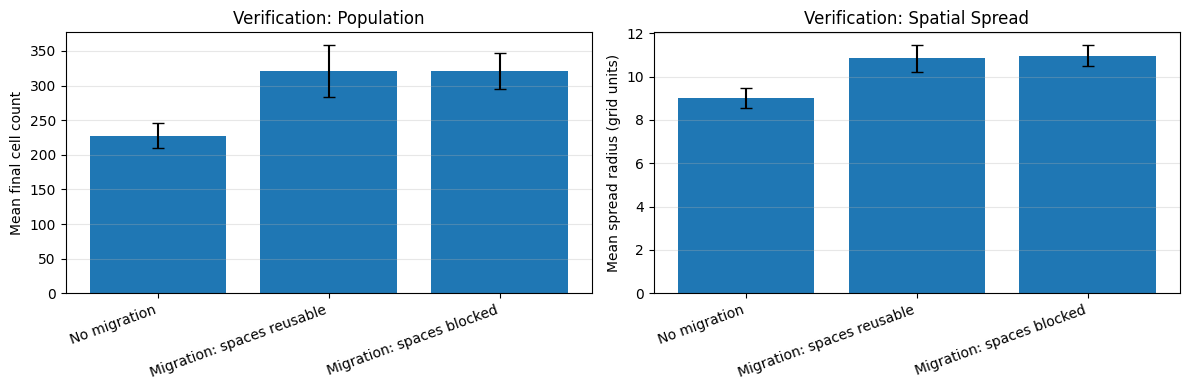

In [9]:
verification_conditions = [
    ("No migration", 0.0, True),
    ("Migration: spaces reusable", 0.10, True),
    ("Migration: spaces blocked", 0.10, False),
]

records_verification = []

for seed in SEEDS:
    for name, p_mig, allow_vacated in verification_conditions:
        grid, history = run_model(
            p_div=0.15,
            p_mig=p_mig,
            seed=seed,
            allow_division_into_migration_vacated=allow_vacated
        )
        records_verification.append({
            "Condition": name,
            "Seed": seed,
            "Final cells": int(grid.sum()),
            "Spread radius": measure_spread(grid)
        })

df_verification = pd.DataFrame(records_verification)

summary_verification = (
    df_verification.groupby("Condition", sort=False)
    .agg(
        Mean_cells=("Final cells", "mean"),
        SD_cells=("Final cells", "std"),
        Mean_spread=("Spread radius", "mean"),
        SD_spread=("Spread radius", "std")
    )
    .reset_index()
)

display(summary_verification.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(summary_verification))
labels = summary_verification["Condition"]

axes[0].bar(
    x,
    summary_verification["Mean_cells"],
    yerr=summary_verification["SD_cells"].fillna(0),
    capsize=4
)
axes[0].set_xticks(x, labels, rotation=20, ha="right")
axes[0].set_ylabel("Mean final cell count")
axes[0].set_title("Verification: Population")
axes[0].grid(True, axis="y", alpha=0.3)

axes[1].bar(
    x,
    summary_verification["Mean_spread"],
    yerr=summary_verification["SD_spread"].fillna(0),
    capsize=4
)
axes[1].set_xticks(x, labels, rotation=20, ha="right")
axes[1].set_ylabel("Mean spread radius (grid units)")
axes[1].set_title("Verification: Spatial Spread")
axes[1].grid(True, axis="y", alpha=0.3)

fig.tight_layout()
fig.savefig("experiment_4_update_rule_check.png", dpi=200, bbox_inches="tight")
plt.show()


### Interpretation — Experiment 4: Sensitivity to Recently Vacated Sites

This experiment examines whether allowing a cell to divide into a site vacated by a migrating cell during the same time step substantially affects the simulation outcomes.

When proliferation is active (\(p_{\mathrm{div}}=0.15\)), the mean final population is 227.8 cells without migration. With migration enabled (\(p_{\mathrm{mig}}=0.10\)), the mean final population increases to 321.4 cells when recently vacated sites can be reused and 321.1 cells when these sites remain unavailable during the same time step.

The difference between the two migration implementations is only 0.3 cells in the mean final population. Their mean spread radii are also similar: 10.84 grid units when recently vacated sites can be reused and 10.95 grid units when they are blocked.

These results suggest that **the treatment of recently vacated sites has little effect on the mean outcomes in this particular implementation**. It therefore does not appear to explain most of the difference in population size between the migration and no-migration conditions.

**Limitation:** This comparison examines only one implementation choice under the selected parameters. The results do not establish the precise mechanisms behind the observed differences. Other spatial interactions and update-order effects may contribute. Furthermore, the experiment uses a limited number of stochastic runs and does not establish statistical significance.

## 11. Exporting Results

The following cell exports the experiment-level results and summary statistics as CSV files for further analysis. Figures can also be saved as PNG files for documentation and reporting.

Files saved in the temporary Google Colab runtime may not persist after the session ends. To retain the results, download the files or save them to Google Drive.

In [10]:
# Save raw data and summary tables
df_migration.to_csv("experiment_1_migration_raw.csv", index=False)
summary_migration.to_csv("experiment_1_migration_summary.csv", index=False)

df_division.to_csv("experiment_2_division_raw.csv", index=False)
summary_division.to_csv("experiment_2_division_summary.csv", index=False)

df_factorial.to_csv("experiment_3_combined_raw.csv", index=False)
summary_factorial.to_csv("experiment_3_combined_summary.csv", index=False)

df_verification.to_csv("experiment_4_verification_raw.csv", index=False)
summary_verification.to_csv("experiment_4_verification_summary.csv", index=False)

print("Saved CSV tables and four PNG figures in the current Colab directory.")
print("Files are available in the Files panel on the left of Colab.")


Saved CSV tables and four PNG figures in the current Colab directory.
Files are available in the Files panel on the left of Colab.


## 12. Overall Conclusions

This project investigated how cell division and migration influence population size and spatial spread in a simplified stochastic cellular automaton model. Four experiments were conducted to examine migration, proliferation, their combined effects, and sensitivity to one implementation choice.

The main findings are as follows:

1. **Effect of migration:** When cell division was disabled, increasing the migration probability from 0 to 0.30 increased the mean spread radius from 2.83 to 7.27 grid units, while the population remained constant at 25 cells. This illustrates how migration can redistribute a fixed population across a larger area.

2. **Effect of proliferation:** With the migration probability fixed at 0.10, increasing the division probability from 0 to 0.20 increased the mean final population from 25 to 478.9 cells. The mean spread radius also increased, from 5.16 to 12.69 grid units. Population growth and spatial spread therefore changed together under the tested conditions.

3. **Combined effects:** At a division probability of 0.15, adding migration with a probability of 0.10 increased the mean final population from 227.8 to 321.4 cells and the mean spread radius from 9.02 to 10.84 grid units, compared with proliferation alone. These differences reflect the behaviour of the implemented model and do not establish a general biological effect of migration on proliferation.

4. **Implementation sensitivity:** Blocking recently vacated sites from being reused during the same time step produced similar results to allowing their reuse. The mean final populations were 321.1 and 321.4 cells, respectively. Under the tested conditions, this implementation choice had little effect on the mean outcomes.

Overall, the simulations demonstrate how simple rules governing cell division and movement can generate different population sizes and spatial distributions. They also illustrate the importance of examining stochastic variability and testing whether conclusions depend on modelling assumptions.

These findings are exploratory. The model has not been calibrated against experimental measurements or validated against biological tumour data. Further work would be needed to determine whether the observed patterns are relevant to real multicellular systems.

### 12.1 Limitations

The model has several limitations:

- **Simplified geometry:** Cells occupy sites on a square lattice and interact through a fixed Moore neighbourhood of eight neighbouring sites.
- **Homogeneous population:** All cells are represented identically, without differences in cell state or behaviour.
- **Limited biological mechanisms:** The model does not include nutrient availability, cell death, treatment effects, extracellular matrix interactions, or physical cell mechanics.
- **Abstract parameters:** Time steps and event probabilities are not calibrated to biological measurements.
- **Simplified spread measure:** Spatial spread is quantified using a geometric radius rather than a validated measure of tumour invasion.
- **Limited stochastic sampling:** Ten simulation runs per condition provide an initial assessment of variability but are insufficient to establish robust statistical conclusions.
- **No biological validation:** The model uses no experimental data for calibration or validation.

### 12.2 Possible Future Extensions

Potential extensions include:

- Introducing nutrient-dependent cell division and cell death.
- Developing a more biologically motivated migration rule.
- Increasing the number of simulation runs and conducting uncertainty analysis.
- Investigating the sensitivity of outcomes to additional model parameters and update rules.
- Comparing model predictions with published experimental data, where suitable data and clearly defined validation criteria are available.

These extensions would require additional assumptions and validation. They are proposed directions for future work, not features of the current model.

## 13. Reproducibility Checklist

Before sharing the notebook:

- [ ] Restart the runtime and run all cells from beginning to end.
- [ ] Confirm that every code cell executes without errors.
- [ ] Check that all tables and figures appear in the appropriate sections.
- [ ] Verify that the random seeds, model parameters, and experimental conditions are documented.
- [ ] Confirm that the interpretations match the final generated results.
- [ ] Ensure that exported files are saved or downloaded if they need to be retained.
- [ ] Keep the model limitations explicit and avoid describing it as a biologically validated tumour model.
- [ ] Give the notebook a clear filename, such as `Cellular_Automaton_Tumour_Spread_Rosin_Jimmy.ipynb`.

**Project description:** A reproducible stochastic cellular automaton study of how proliferation and migration probabilities influence cell-population size and spatial spread under simplified lattice-model assumptions.